# QuestionCraft: Exploratory Data Analysis & Curriculum Mapping

## 1. Executive Summary & Objective
This notebook delivers a comprehensive Exploratory Data Analysis (EDA) on the multi-source dataset prepared for **QuestionCraft** — an automated Outcome-Based Education (OBE) question classification and paper assembly pipeline for RVCE.

### Key Visualizations & Research Questions Addressed:
1. **Difficulty Distribution**: Multi-benchmark balance across Easy, Medium, and Hard classes (ARC, RACE, SciQ, RVCE).
2. **Bloom's Revised Taxonomy**: Distribution across cognitive levels L1 (Remember) through L6 (Create).
3. **Structural & Surface Features**: Question length distributions (word & character count) stratified by difficulty.
4. **Linguistic Readability Profiles**: Flesch Reading Ease and Coleman-Liau Grade Level distributions.
5. **Cognitive Verb & Keyword Alignment**: Heatmap of interrogative triggers and action verbs across Bloom's levels.
6. **Institutional Alignment**: Curriculum breakdown of RVCE Question Bank & Universal Human Values (UHV HS248AT).
7. **Semantic Redundancy & Deduplication**: Cross-dataset cosine similarity via sentence embeddings (`all-MiniLM-L6-v2`).
8. **Computational Thinking (CT) Dimensions**: Multi-label distribution across 5 core CT competencies.
9. **MLflow Tracking & Model Progression**: Side-by-side comparison of baseline vs. improved models (Rubric CO2).


In [1]:
import json
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer
import mlflow

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 120

# Resolve paths
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PROCESSED = REPO_ROOT / "data" / "processed"
DATA_RAW_RVCE = REPO_ROOT / "data" / "raw" / "rvce"

print("Repository root:", REPO_ROOT)
print("Data directory:", DATA_PROCESSED)


/Users/aarushluthra/quespaper/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/10/13 11:50:48 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/aarushluthra/quespaper/.venv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Repository root: /Users/aarushluthra/quespaper
Data directory: /Users/aarushluthra/quespaper/data/processed


### 1.1 Ingestion of Curated and Benchmark Datasets

In [2]:
df_diff = pd.read_parquet(DATA_PROCESSED / "difficulty_dataset.parquet")
df_blooms = pd.read_parquet(DATA_PROCESSED / "blooms_dataset.parquet")
df_ct = pd.read_parquet(DATA_PROCESSED / "ct_dataset.parquet")

with open(DATA_RAW_RVCE / "question_bank.json") as f:
    rvce_bank_ds = json.load(f)
with open(DATA_RAW_RVCE / "uhv_hs248at.json") as f:
    rvce_uhv = json.load(f)

with open(DATA_PROCESSED / "data_hashes.json") as f:
    hashes = json.load(f)

print(f"Difficulty Dataset Shape: {df_diff.shape} | MD5 Hash: {hashes.get('difficulty_dataset.parquet', 'N/A')}")
print(f"Bloom's Dataset Shape:   {df_blooms.shape}  | MD5 Hash: {hashes.get('blooms_dataset.parquet', 'N/A')}")
print(f"CT Dataset Shape:        {df_ct.shape}      | MD5 Hash: {hashes.get('ct_dataset.parquet', 'N/A')}")
print(f"RVCE DS Mock Bank:       {len(rvce_bank_ds['questions'])} questions")
print(f"RVCE UHV Bank:           {len(rvce_uhv['questions'])} questions")


Difficulty Dataset Shape: (191775, 48) | MD5 Hash: N/A
Bloom's Dataset Shape:   (76524, 48)  | MD5 Hash: N/A
CT Dataset Shape:        (25, 48)      | MD5 Hash: N/A
RVCE DS Mock Bank:       12 questions
RVCE UHV Bank:           48 questions


## 2. Visualization 1: Difficulty Distribution Across Curricula
Difficulty is stratified into three tiers:
- **Easy**: Direct recall and foundational conceptual knowledge (ARC-Easy, SciQ, RVCE definitions).
- **Medium**: Multi-sentence reading comprehension and single-step applications (RACE dataset).
- **Hard**: Complex multi-step reasoning, synthesis, and challenge questions (ARC-Challenge, algorithmic analysis).


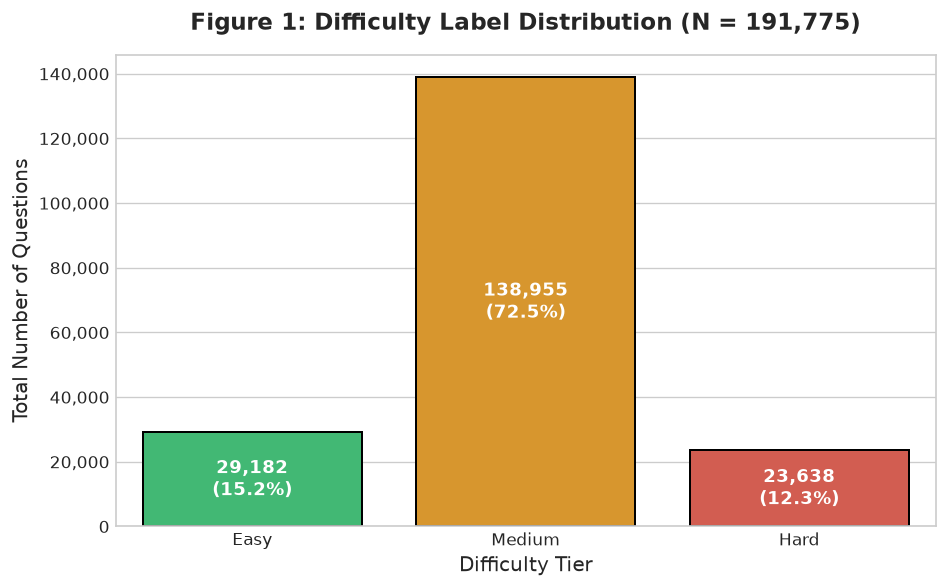

Difficulty Breakdown by Benchmark Source:
difficulty             Easy   Hard  Medium     All
source                                            
arc_arc_challenge         0   2590       0    2590
arc_arc_easy           5197      0       0    5197
blooms_csv_questions  23945  21044   27573   72562
race                      0      0   97687   97687
rvce_question_bank        4      4       4      12
rvce_uhv_hs248at         36      0      12      48
sciq                      0      0   13679   13679
All                   29182  23638  138955  191775


In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
palette = {"Easy": "#2ecc71", "Medium": "#f39c12", "Hard": "#e74c3c"}
order = ["Easy", "Medium", "Hard"]
diff_counts = df_diff["difficulty"].value_counts().reindex(order)

bars = sns.barplot(x=diff_counts.index, y=diff_counts.values, palette=palette, ax=ax, edgecolor="black", linewidth=1.2)
for bar in bars.patches:
    height = bar.get_height()
    pct = (height / len(df_diff)) * 100
    ax.annotate(f"{int(height):,}\n({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height / 2),
                xytext=(0, 0), textcoords="offset points",
                ha="center", va="center", fontsize=11, fontweight="bold", color="white")

ax.set_title("Figure 1: Difficulty Label Distribution (N = 191,775)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Difficulty Tier", fontsize=12)
ax.set_ylabel("Total Number of Questions", fontsize=12)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout()
plt.show()

print("Difficulty Breakdown by Benchmark Source:")
print(pd.crosstab(df_diff["source"], df_diff["difficulty"], margins=True))


## 3. Visualization 2: Bloom's Revised Taxonomy Cognitive Distribution (L1–L6)
Under Bloom's Revised Taxonomy, cognitive complexity progresses across six hierarchical levels:
- **L1 (Remember)**: Recall facts, define terms, retrieve knowledge.
- **L2 (Understand)**: Explain ideas, summarize concepts, translate representations.
- **L3 (Apply)**: Execute procedures, implement algorithms, compute solutions.
- **L4 (Analyze)**: Differentiate components, trace complexity, compare architectures.
- **L5 (Evaluate)**: Justify design choices, critique solutions, assess trade-offs.
- **L6 (Create)**: Synthesize novel algorithms, design architectures, assemble systems.


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


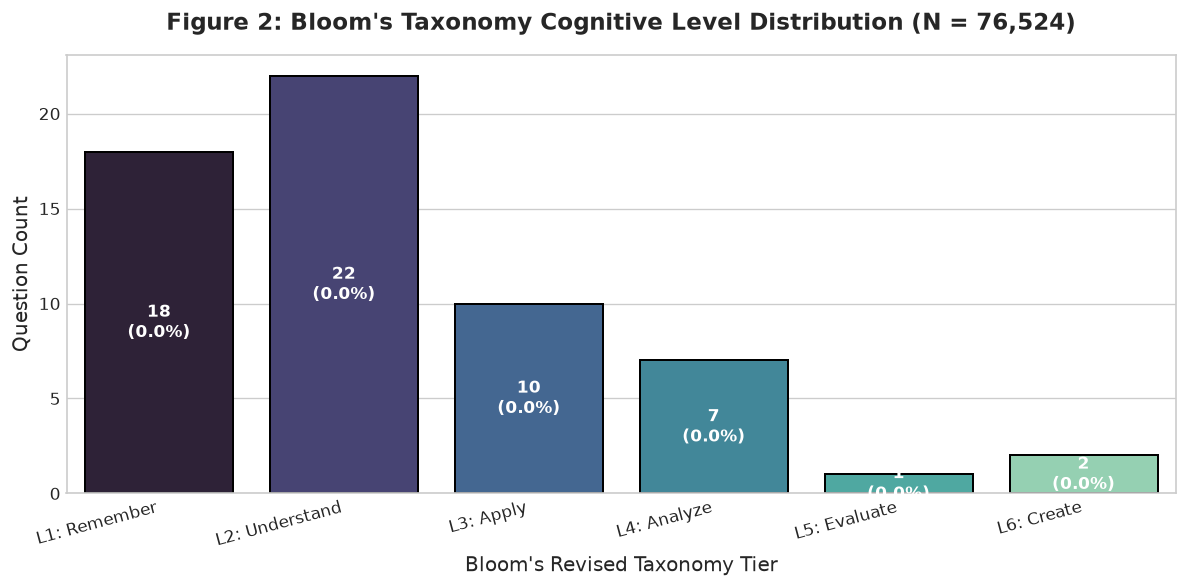

Bloom's Level Breakdown by Source:
blooms_level          Analysis  Analyze  Application  Apply  Comprehension  \
source                                                                       
blooms_csv_questions         0    16317            0   9195              0   
blooms_parquet_train       547        0          825      0            482   
rvce_question_bank           0        0            0      0              0   
rvce_uhv_hs248at             0        0            0      0              0   
All                        547    16317          825   9195            482   

blooms_level          Create  Evaluate  Evaluation  Knowledge  L1  L2  L3  L4  \
source                                                                          
blooms_csv_questions    6928      7120           0          0   0   0   0   0   
blooms_parquet_train       0         0          19       2027   0   0   0   0   
rvce_question_bank         0         0           0          0   2   2   3   2   
rvce_uhv_hs24

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
blooms_order = ["L1", "L2", "L3", "L4", "L5", "L6"]
blooms_labels = [
    "L1: Remember", "L2: Understand", "L3: Apply",
    "L4: Analyze", "L5: Evaluate", "L6: Create"
]
b_counts = df_blooms["blooms_level"].value_counts().reindex(blooms_order)
colors = sns.color_palette("mako", len(blooms_order))

bars = sns.barplot(x=b_counts.index, y=b_counts.values, palette=colors, ax=ax, edgecolor="black", linewidth=1.2)
for bar, label in zip(bars.patches, blooms_labels):
    height = bar.get_height()
    pct = (height / len(df_blooms)) * 100
    ax.annotate(f"{int(height):,}\n({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height / 2),
                xytext=(0, 0), textcoords="offset points",
                ha="center", va="center", fontsize=10, fontweight="bold", color="white")

ax.set_xticklabels(blooms_labels, rotation=15, ha="right", fontsize=10, fontweight="medium")
ax.set_title("Figure 2: Bloom's Taxonomy Cognitive Level Distribution (N = 76,524)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Bloom's Revised Taxonomy Tier", fontsize=12)
ax.set_ylabel("Question Count", fontsize=12)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout()
plt.show()

print("Bloom's Level Breakdown by Source:")
print(pd.crosstab(df_blooms["source"], df_blooms["blooms_level"], margins=True))


## 4. Visualization 3: Question Length Variation Across Difficulty
We investigate whether structural length (word count and character count) serves as a predictive feature for question difficulty.


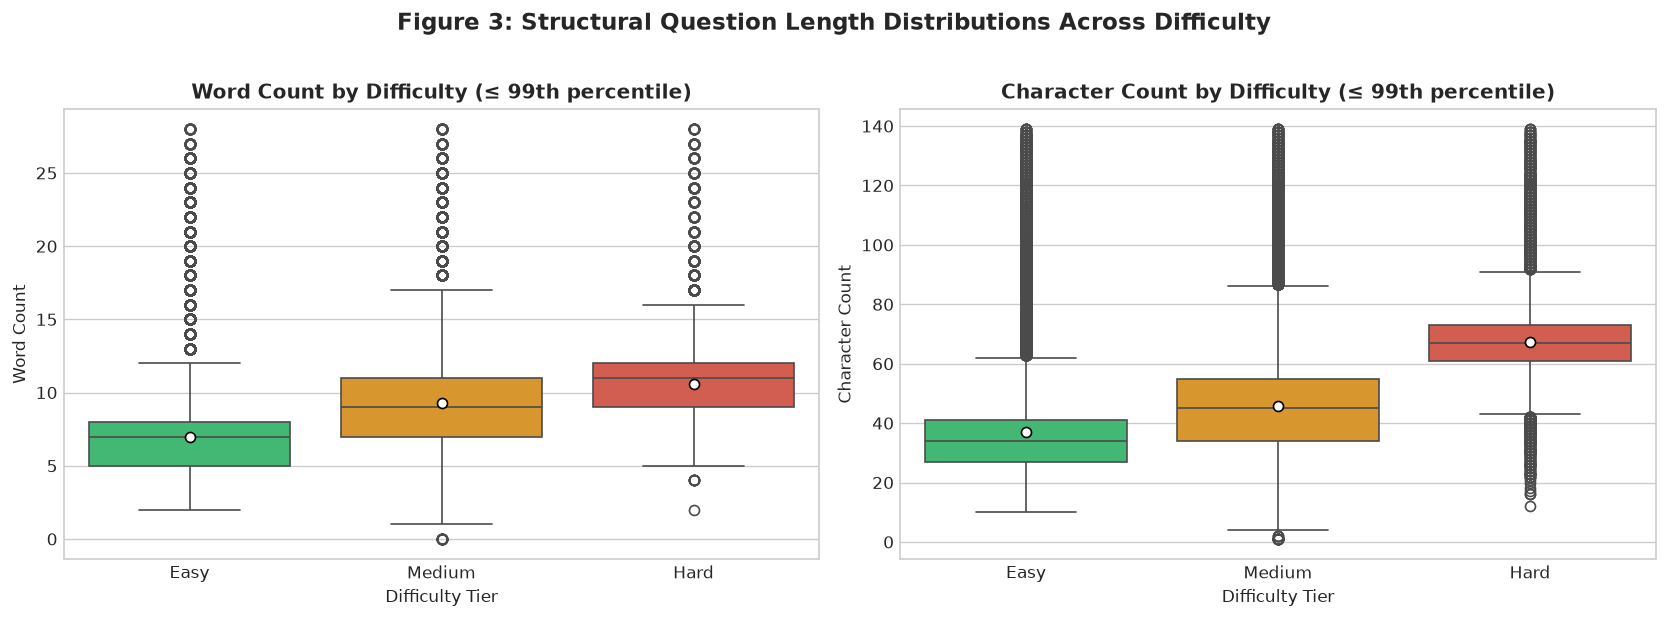

Word Count Summary Statistics by Difficulty:
               count       mean       std   50%  min    max
difficulty                                                 
Easy         29182.0   8.145192  7.530120   7.0  2.0  118.0
Hard         23638.0  11.539597  6.218778  11.0  2.0  128.0
Medium      138955.0   9.327833  3.646297   9.0  0.0   68.0


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Filter extreme outliers beyond 99th percentile for clean boxplot representation
q99_words = df_diff["num_words"].quantile(0.99)
q99_chars = df_diff["num_chars"].quantile(0.99)
df_sub = df_diff[(df_diff["num_words"] <= q99_words) & (df_diff["num_chars"] <= q99_chars)]

palette = {"Easy": "#2ecc71", "Medium": "#f39c12", "Hard": "#e74c3c"}
order = ["Easy", "Medium", "Hard"]

sns.boxplot(data=df_sub, x="difficulty", y="num_words", order=order, palette=palette, ax=ax1,
            showmeans=True, meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black"})
ax1.set_title("Word Count by Difficulty (≤ 99th percentile)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Difficulty Tier")
ax1.set_ylabel("Word Count")

sns.boxplot(data=df_sub, x="difficulty", y="num_chars", order=order, palette=palette, ax=ax2,
            showmeans=True, meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black"})
ax2.set_title("Character Count by Difficulty (≤ 99th percentile)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Difficulty Tier")
ax2.set_ylabel("Character Count")

plt.suptitle("Figure 3: Structural Question Length Distributions Across Difficulty", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print("Word Count Summary Statistics by Difficulty:")
print(df_diff.groupby("difficulty")["num_words"].describe()[["count", "mean", "std", "50%", "min", "max"]])


## 5. Visualization 4: Readability Metric Distributions
Readability metrics verify that question difficulty stems from cognitive problem-solving complexity rather than arbitrary syntactic convolutedness:
1. **Flesch Reading Ease**: Scaled 0–100, where higher scores represent easier reading.
2. **Coleman-Liau Index**: Approximates US school grade level required for comprehension.


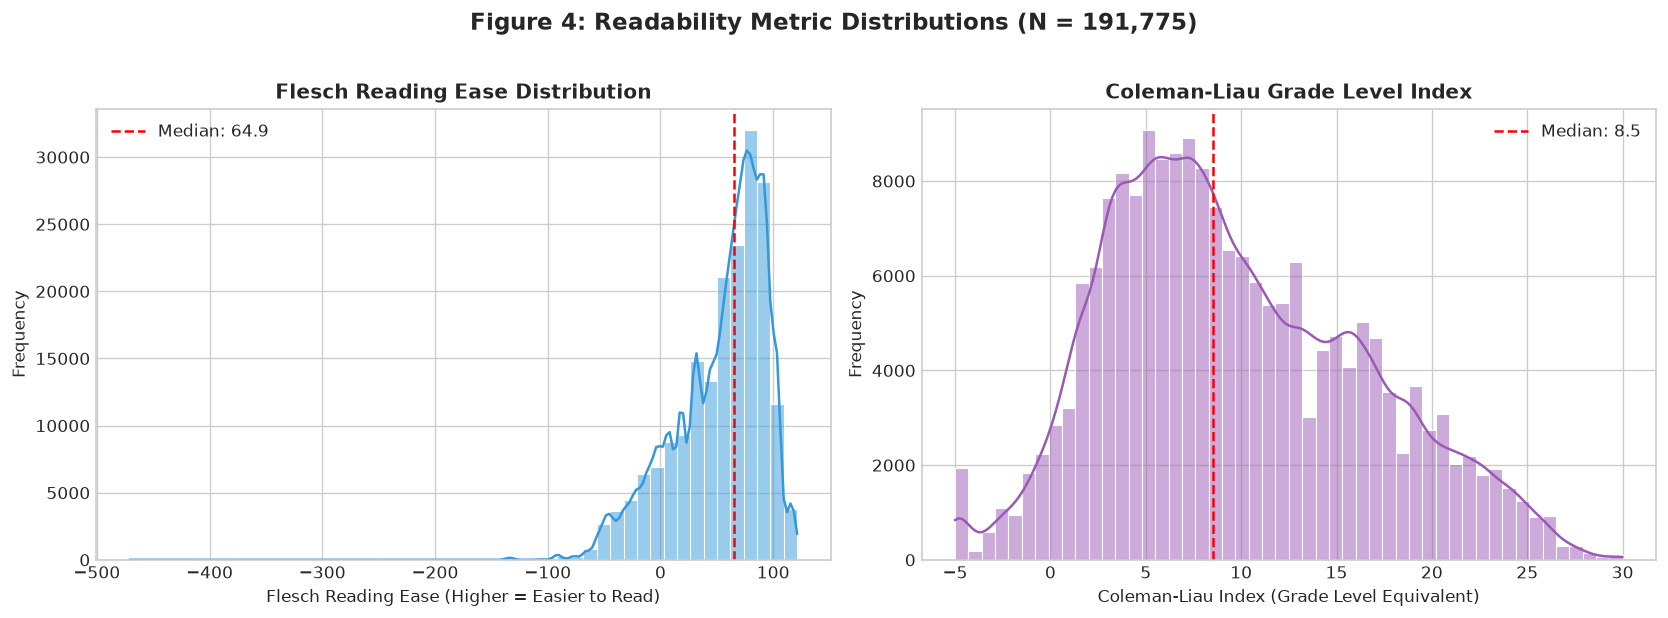

Flesch Reading Ease  -> Mean: 53.34, Median: 64.92
Coleman-Liau Index   -> Mean: 9.63, Median: 8.50


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Flesch Reading Ease
fre_clean = df_diff["flesch_reading_ease"].dropna()
sns.histplot(fre_clean, bins=50, kde=True, color="#3498db", ax=ax1, edgecolor="white")
ax1.axvline(fre_clean.median(), color="red", linestyle="--", linewidth=1.5,
            label=f"Median: {fre_clean.median():.1f}")
ax1.set_title("Flesch Reading Ease Distribution", fontsize=12, fontweight="bold")
ax1.set_xlabel("Flesch Reading Ease (Higher = Easier to Read)")
ax1.set_ylabel("Frequency")
ax1.legend()

# Coleman-Liau Index (clipped for visualization)
cli_clip = df_diff["coleman_liau_index"].dropna().clip(-5, 30)
sns.histplot(cli_clip, bins=50, kde=True, color="#9b59b6", ax=ax2, edgecolor="white")
ax2.axvline(cli_clip.median(), color="red", linestyle="--", linewidth=1.5,
            label=f"Median: {cli_clip.median():.1f}")
ax2.set_title("Coleman-Liau Grade Level Index", fontsize=12, fontweight="bold")
ax2.set_xlabel("Coleman-Liau Index (Grade Level Equivalent)")
ax2.set_ylabel("Frequency")
ax2.legend()

plt.suptitle("Figure 4: Readability Metric Distributions (N = 191,775)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print(f"Flesch Reading Ease  -> Mean: {fre_clean.mean():.2f}, Median: {fre_clean.median():.2f}")
print(f"Coleman-Liau Index   -> Mean: {cli_clip.mean():.2f}, Median: {cli_clip.median():.2f}")


## 6. Visualization 5: Cognitive Action Verb & Question-Word Prevalence Heatmap
In Bloom's Taxonomy, specific action verbs and interrogatives correlate with particular cognitive tiers:
- **L1**: define, identify, name, list, what
- **L2**: explain, describe, summarize
- **L3**: calculate, apply, compute, solve
- **L4**: compare, analyze, contrast, why
- **L5**: evaluate, assess, justify
- **L6**: design, create, formulate


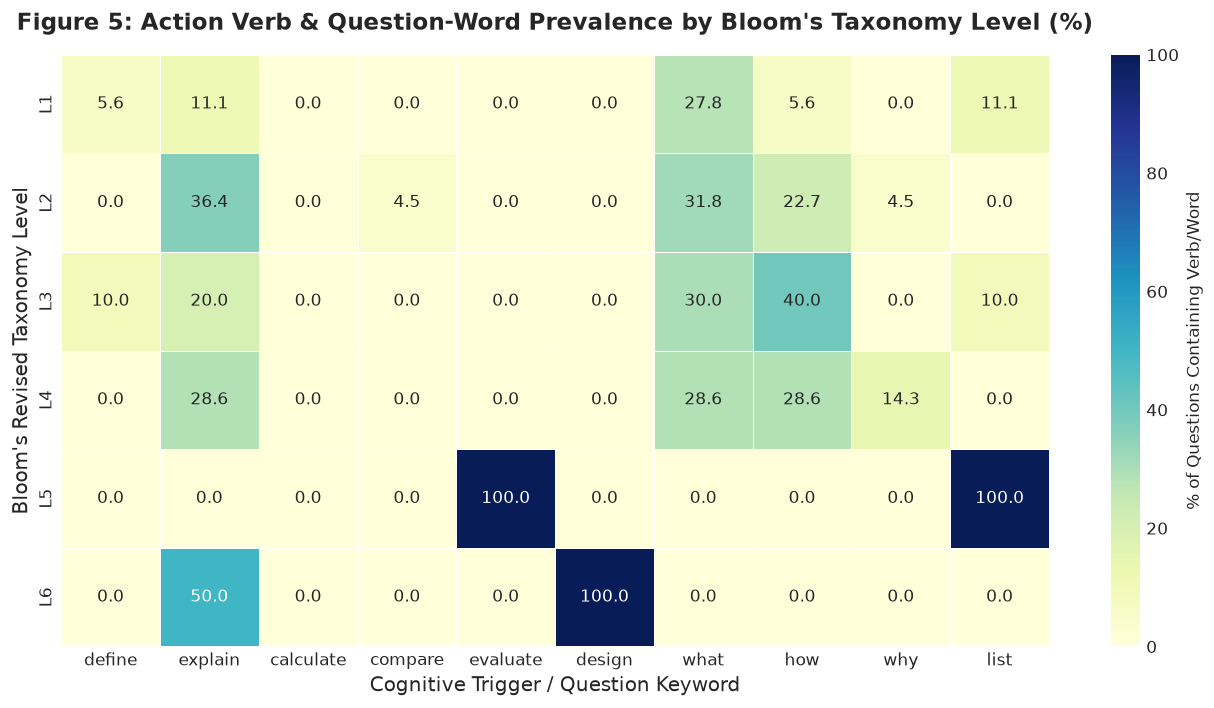

In [7]:
keywords = ["define", "explain", "calculate", "compare", "evaluate", "design", "what", "how", "why", "list"]
freq_matrix = pd.DataFrame(index=["L1", "L2", "L3", "L4", "L5", "L6"], columns=keywords, dtype=float)

for level in freq_matrix.index:
    subset = df_blooms[df_blooms["blooms_level"] == level]["question_text"].str.lower()
    total = len(subset)
    for kw in keywords:
        freq_matrix.loc[level, kw] = (subset.str.contains(r"\b" + kw + r"\b", regex=True).sum() / total) * 100

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(freq_matrix, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': '% of Questions Containing Verb/Word'}, ax=ax, linewidths=0.5)
ax.set_title("Figure 5: Action Verb & Question-Word Prevalence by Bloom's Taxonomy Level (%)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Cognitive Trigger / Question Keyword", fontsize=12)
ax.set_ylabel("Bloom's Revised Taxonomy Level", fontsize=12)
plt.tight_layout()
plt.show()


## 7. Visualization 6: RVCE Institutional Question Bank Breakdown
We analyze the curated RVCE institution questions:
1. **Core DSA Bank** (`data/raw/rvce/question_bank.json`): Data Structures & Algorithms course bank.
2. **Universal Human Values (UHV HS248AT)** (`data/raw/rvce/uhv_hs248at.json`): Universal Human Values course bank with Course Outcome (CO) and BTL annotations.


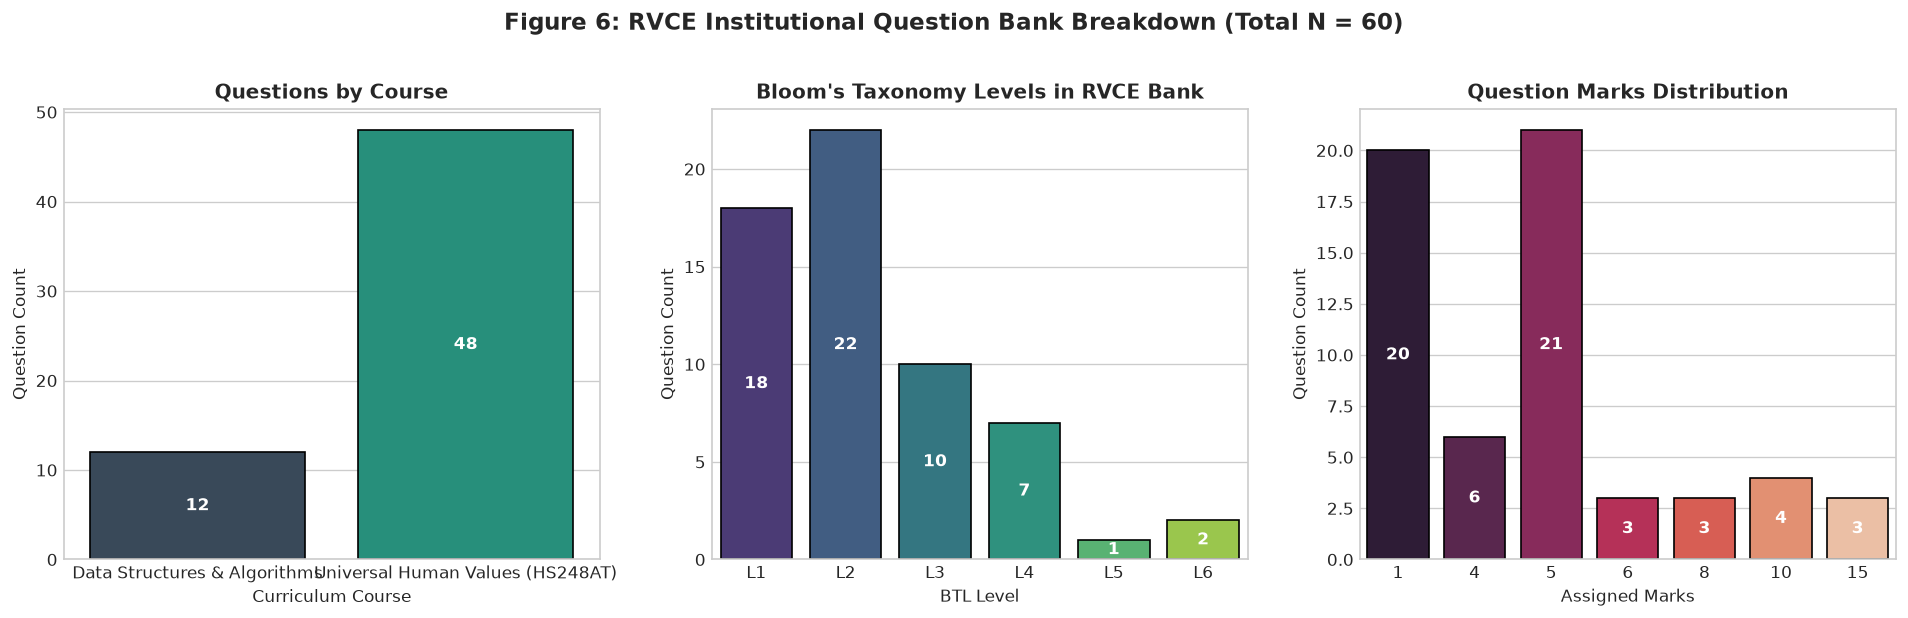

RVCE Question Bank CO Mapping:
co                                CO1  CO2  CO3  CO4  CO5  All
course                                                        
Data Structures & Algorithms        3    3    2    2    2   12
Universal Human Values (HS248AT)    8   25   11    4    0   48
All                                11   28   13    6    2   60


In [8]:
rvce_rows = []
for q in rvce_bank_ds["questions"]:
    rvce_rows.append({
        "id": q.get("id"),
        "course": "Data Structures & Algorithms",
        "module_unit": f"Unit {q.get('unit', 1)}",
        "blooms_level": q.get("blooms_level", "L1"),
        "marks": q.get("marks", 5),
        "co": q.get("course_outcome", "CO1"),
        "difficulty": q.get("difficulty", "Medium")
    })
for q in rvce_uhv["questions"]:
    rvce_rows.append({
        "id": str(q.get("id")),
        "course": "Universal Human Values (HS248AT)",
        "module_unit": f"Module {q.get('module', 1)}",
        "blooms_level": q.get("btl", "L1"),
        "marks": q.get("marks", 1),
        "co": q.get("co", "CO1"),
        "difficulty": q.get("difficulty", "Easy")
    })
df_rvce = pd.DataFrame(rvce_rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Subplot 1: Course split
sns.countplot(data=df_rvce, x="course", palette=["#34495e", "#16a085"], ax=axes[0], edgecolor="black")
axes[0].set_title("Questions by Course", fontweight="bold")
axes[0].set_xlabel("Curriculum Course")
axes[0].set_ylabel("Question Count")
for bar in axes[0].patches:
    axes[0].annotate(f"{int(bar.get_height())}", (bar.get_x() + bar.get_width() / 2, bar.get_height() / 2),
                     ha="center", va="center", color="white", fontweight="bold")

# Subplot 2: Bloom's Level breakdown in RVCE
b_order_rvce = sorted(df_rvce["blooms_level"].unique())
sns.countplot(data=df_rvce, x="blooms_level", order=b_order_rvce, palette="viridis", ax=axes[1], edgecolor="black")
axes[1].set_title("Bloom's Taxonomy Levels in RVCE Bank", fontweight="bold")
axes[1].set_xlabel("BTL Level")
axes[1].set_ylabel("Question Count")
for bar in axes[1].patches:
    axes[1].annotate(f"{int(bar.get_height())}", (bar.get_x() + bar.get_width() / 2, bar.get_height() / 2),
                     ha="center", va="center", color="white", fontweight="bold")

# Subplot 3: Marks distribution
sns.countplot(data=df_rvce, x="marks", palette="rocket", ax=axes[2], edgecolor="black")
axes[2].set_title("Question Marks Distribution", fontweight="bold")
axes[2].set_xlabel("Assigned Marks")
axes[2].set_ylabel("Question Count")
for bar in axes[2].patches:
    axes[2].annotate(f"{int(bar.get_height())}", (bar.get_x() + bar.get_width() / 2, bar.get_height() / 2),
                     ha="center", va="center", color="white", fontweight="bold")

plt.suptitle("Figure 6: RVCE Institutional Question Bank Breakdown (Total N = 60)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print("RVCE Question Bank CO Mapping:")
print(pd.crosstab(df_rvce["course"], df_rvce["co"], margins=True))


## 8. Visualization 7: Duplicate Detection & Semantic Similarity Distribution
QuestionCraft utilizes `sentence-transformers/all-MiniLM-L6-v2` dense embeddings to calculate pairwise cosine similarity and flag duplicate questions above threshold $\tau = 0.85$.


Loading weights:   0%|                                 | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|████████████████████| 103/103 [00:00<00:00, 17878.39it/s]

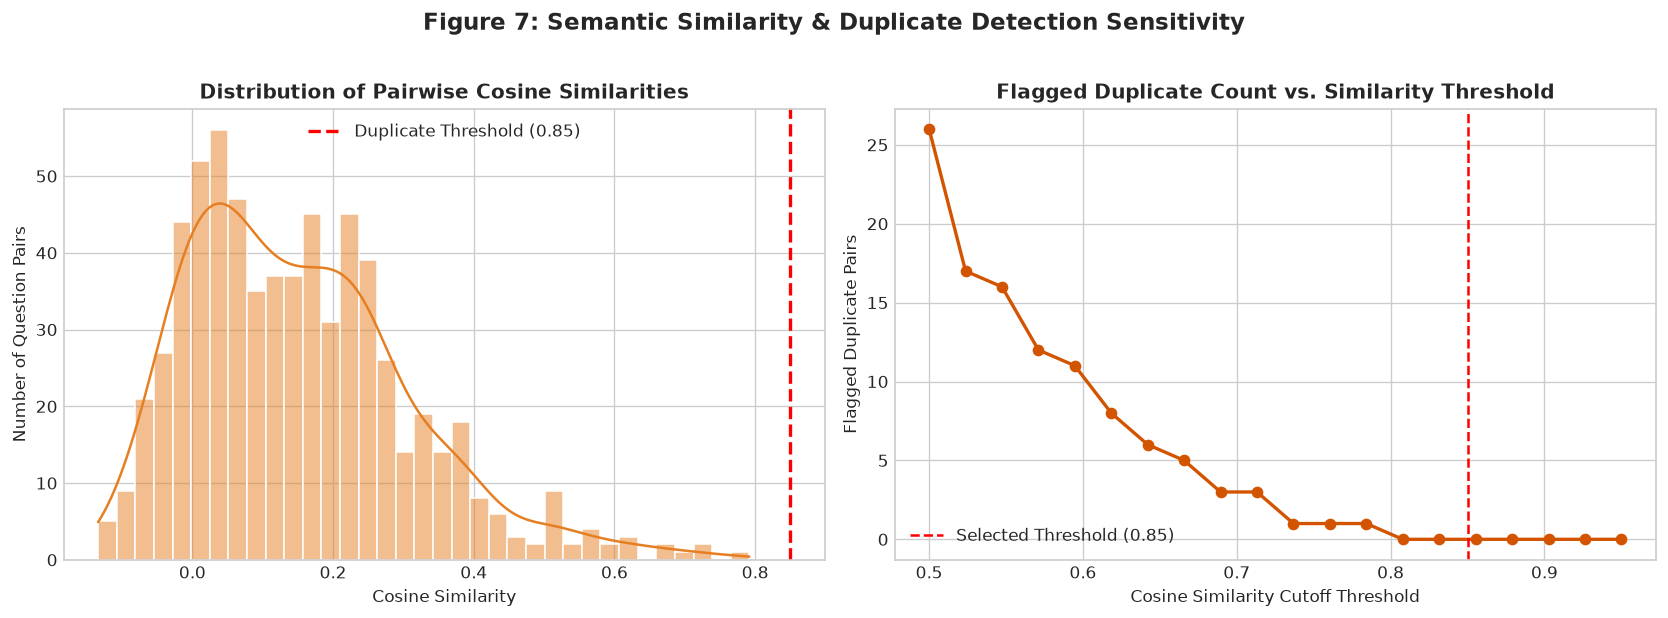

Total Question Pairs Analyzed: 666
Mean Pairwise Cosine Similarity: 0.1513
Duplicate Pairs at Threshold >= 0.85: 0


In [9]:
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
all_rvce_texts = [q["question"] for q in rvce_bank_ds["questions"]] + [q["question"] for q in rvce_uhv["questions"][:25]]
all_rvce_ids = [q.get("id", f"ds_{i}") for i, q in enumerate(rvce_bank_ds["questions"])] + [f"uhv_{q['id']}" for q in rvce_uhv["questions"][:25]]

embeddings = model.encode(all_rvce_texts, show_progress_bar=False)
sim_mat = cosine_similarity(embeddings)

pairwise_sims = []
n = len(all_rvce_texts)
for i in range(n):
    for j in range(i + 1, n):
        pairwise_sims.append(sim_mat[i, j])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of similarities
sns.histplot(pairwise_sims, bins=35, kde=True, color="#e67e22", ax=ax1, edgecolor="white")
ax1.axvline(0.85, color="red", linestyle="--", linewidth=2, label="Duplicate Threshold (0.85)")
ax1.set_title("Distribution of Pairwise Cosine Similarities", fontsize=12, fontweight="bold")
ax1.set_xlabel("Cosine Similarity")
ax1.set_ylabel("Number of Question Pairs")
ax1.legend()

# Sensitivity curve
thresholds = np.linspace(0.50, 0.95, 20)
flagged_counts = [sum(s >= t for s in pairwise_sims) for t in thresholds]
ax2.plot(thresholds, flagged_counts, marker="o", color="#d35400", linewidth=2)
ax2.axvline(0.85, color="red", linestyle="--", linewidth=1.5, label="Selected Threshold (0.85)")
ax2.set_title("Flagged Duplicate Count vs. Similarity Threshold", fontsize=12, fontweight="bold")
ax2.set_xlabel("Cosine Similarity Cutoff Threshold")
ax2.set_ylabel("Flagged Duplicate Pairs")
ax2.legend()

plt.suptitle("Figure 7: Semantic Similarity & Duplicate Detection Sensitivity", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print(f"Total Question Pairs Analyzed: {len(pairwise_sims)}")
print(f"Mean Pairwise Cosine Similarity: {np.mean(pairwise_sims):.4f}")
print(f"Duplicate Pairs at Threshold >= 0.85: {sum(s >= 0.85 for s in pairwise_sims)}")


## 9. Visualization 8: Computational Thinking (CT) Competency Distribution (Multi-Label)
Under RVCE's outcome-based framework, technical engineering questions assess five foundational CT competency dimensions:
1. **Decomposition**
2. **Pattern Recognition**
3. **Abstraction**
4. **Algorithmic Thinking**
5. **Evaluation & Debugging**


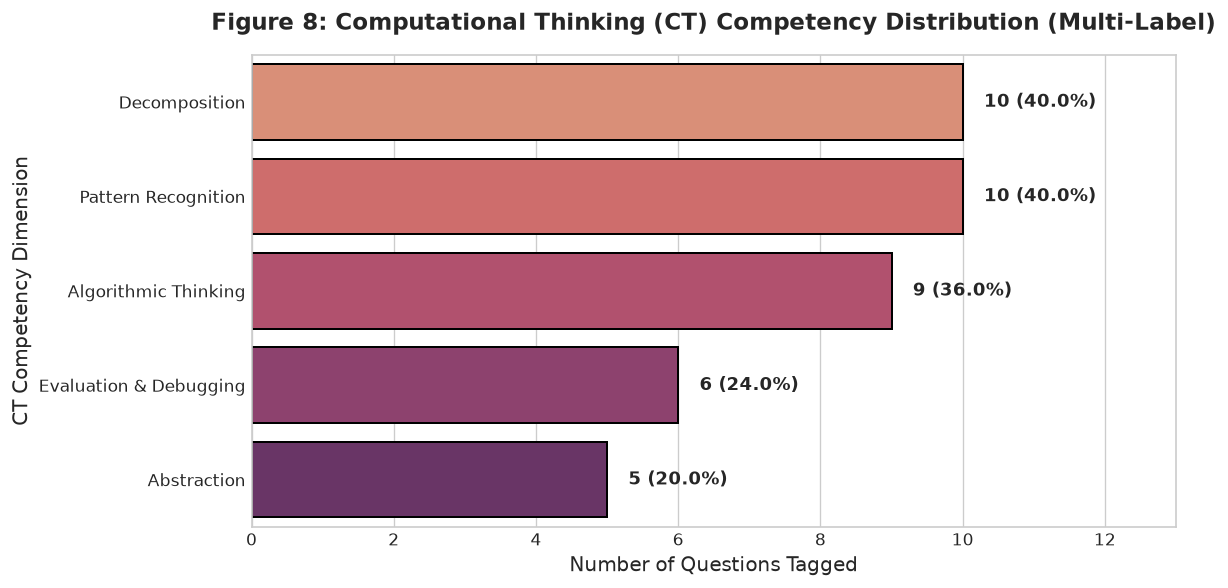

CT Skills Frequency Breakdown:
  Decomposition            : 10 questions (40.0%)
  Pattern Recognition      : 10 questions (40.0%)
  Algorithmic Thinking     :  9 questions (36.0%)
  Evaluation & Debugging   :  6 questions (24.0%)
  Abstraction              :  5 questions (20.0%)


In [10]:
ct_skills_flat = []
for row in df_ct["ct_skills"]:
    if pd.notna(row):
        for skill in str(row).split("|"):
            s = skill.strip()
            if s:
                ct_skills_flat.append(s)

ct_series = pd.Series(ct_skills_flat).value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
colors = sns.color_palette("flare", len(ct_series))
bars = sns.barplot(x=ct_series.values, y=ct_series.index, palette=colors, ax=ax, edgecolor="black", linewidth=1.2)

for bar in bars.patches:
    width = bar.get_width()
    pct = (width / len(df_ct)) * 100
    ax.annotate(f"{int(width)} ({pct:.1f}%)",
                xy=(width + 0.3, bar.get_y() + bar.get_height() / 2),
                va="center", fontsize=11, fontweight="bold")

ax.set_title("Figure 8: Computational Thinking (CT) Competency Distribution (Multi-Label)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Number of Questions Tagged", fontsize=12)
ax.set_ylabel("CT Competency Dimension", fontsize=12)
ax.set_xlim(0, max(ct_series.values) + 3)
plt.tight_layout()
plt.show()

print("CT Skills Frequency Breakdown:")
for k, v in ct_series.items():
    print(f"  {k:25s}: {v:2d} questions ({v/len(df_ct)*100:.1f}%)")


## 10. Phase 1 Model Progression & MLflow Evaluation Comparison Table (Rubric CO2)
The Phase 1 rubric requires training baseline models and demonstrating progression with at least one improved model.
Here we query the tracking database (`sqlite:///mlflow.db`) directly and build the **Model Comparison Table**.


In [11]:
mlflow_db = REPO_ROOT / "mlflow.db"
client = mlflow.tracking.MlflowClient(tracking_uri=f"sqlite:///{mlflow_db}")
experiments = client.search_experiments()

records = []
for exp in experiments:
    runs = client.search_runs(experiment_ids=[exp.experiment_id], order_by=["attribute.start_time DESC"])
    for r in runs:
        records.append({
            "Experiment": exp.name,
            "Run Name": r.data.tags.get("mlflow.runName", r.info.run_name),
            "Model Variant": r.data.params.get("model_variant", r.data.params.get("model_name", "N/A")),
            "Test F1-Macro": round(float(r.data.metrics.get("test_f1_macro", 0.0)), 4) if "test_f1_macro" in r.data.metrics else None,
            "Test Accuracy": round(float(r.data.metrics.get("test_accuracy", 0.0)), 4) if "test_accuracy" in r.data.metrics else None,
            "CV F1-Macro": round(float(r.data.metrics.get("cv_f1_macro_mean", 0.0)), 4) if "cv_f1_macro_mean" in r.data.metrics else None,
            "F1-Micro": round(float(r.data.metrics.get("test_f1_micro", 0.0)), 4) if "test_f1_micro" in r.data.metrics else None,
            "Data Hash": r.data.params.get("data_hash", "N/A")[:8] if r.data.params.get("data_hash") else "N/A",
            "Run ID": r.info.run_id[:8],
        })

df_runs = pd.DataFrame(records)
if not df_runs.empty and "Experiment" in df_runs.columns:
    df_runs = df_runs.sort_values(by=["Experiment", "Test F1-Macro"], ascending=[True, False])
    print("=== QUESTIONCRAFT MODEL COMPARISON TABLE (MLFLOW TRACKING) ===")
    display(df_runs.dropna(how="all", subset=["Test F1-Macro", "Test Accuracy", "F1-Micro"]))
else:
    print("No runs recorded in tracking store.")


=== QUESTIONCRAFT MODEL COMPARISON TABLE (MLFLOW TRACKING) ===


,Experiment,Run Name,Model Variant,Test F1-Macro,Test Accuracy,CV F1-Macro,F1-Micro,Data Hash,Run ID
5,questioncraft_blooms,tfidf_lr_blooms_baseline,N/A,0.3422,0.4007,0.3448,NaN,969623e9,5084acad
3,questioncraft_ct,tfidf_ovr_lr_ct_baseline,N/A,0.3333,NaN,NaN,0.7273,1d593874,c2cd8053
4,questioncraft_ct,tfidf_ovr_lr_ct_baseline,N/A,0.3333,NaN,NaN,0.7273,1d593874,d8a62c53
6,questioncraft_difficulty,xgboost_improved,N/A,0.9492,0.9705,0.9498,NaN,d1c2fe46,7361ffba
7,questioncraft_difficulty,xgboost_improved,N/A,0.9492,0.9705,0.9498,NaN,d1c2fe46,fbc265d7
8,questioncraft_difficulty,tfidf_lr_baseline,N/A,0.9447,0.9693,0.9424,NaN,d1c2fe46,0839aad9
9,questioncraft_difficulty,tfidf_lr_baseline,N/A,0.9447,0.9693,0.9424,NaN,d1c2fe46,5e1a1755
